# Milestone 1: Exploration & Cleaning

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# To display plots directly in the notebook
%matplotlib inline

In [ ]:
df = pd.read_csv('data/kc_house_data.csv')

# Display the first 5 rows
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
# Display the number of rows and columns
print("DataFrame dimensions:", df.shape)

# Display data types and non-null values
df.info()

# Count missing values per column
print("\nMissing values per column:\n", df.isnull().sum())

DataFrame dimensions: (21613, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            2

### Column Meanings and Data Type Analysis

Here is the description of each column in the dataset (KC House Sales) and an analysis of the relevance of their current data types:

| Column Name | Description | Current Type | Analysis and Recommendations |
| :--- | :--- | :--- | :--- |
| **id** | Unique identifier for each house sale. | `int64` | **Appropriate**, but as it is an identifier, we will not perform numerical calculations on it. |
| **date** | Date when the house was sold. | `object` (text) | **Not optimal**. It should be converted to `datetime64` to facilitate filtering and extracting time-based features. |
| **price** | Sale price of the house (Target variable). | `float64` | **Appropriate** for a continuous target variable. |
| **bedrooms** | Number of bedrooms. | `int64` | **Appropriate**. |
| **bathrooms** | Number of bathrooms (can be decimal, e.g., 2.25). | `float64` | **Appropriate** because partial bathrooms exist (e.g., half-baths without a shower). |
| **sqft_living** | Interior living space square footage. | `int64` | **Appropriate**. |
| **sqft_lot** | Land lot square footage. | `int64` | **Appropriate**. |
| **floors** | Number of floors in the house. | `float64` | **Appropriate** because some houses have half floors (e.g., 1.5 or 2.5 floors). |
| **waterfront** | Binary variable indicating whether the house has a waterfront view (0 = No, 1 = Yes). | `int64` | **Appropriate**, but could also be represented as a boolean or categorical variable. |
| **view** | Rating of the quality of the view from the property (from 0 to 4). | `int64` | **Appropriate** as an ordinal integer rating. |
| **condition** | Rating on the overall condition of the house (from 1 to 5). | `int64` | **Appropriate** as an ordinal integer rating. |
| **grade** | Overall grade given to the housing unit based on the King County construction grading system (from 1 to 13). | `int64` | **Appropriate** as an ordinal integer rating. |
| **sqft_above** | Square footage of the house space that is above ground level. | `int64` | **Appropriate**. |
| **sqft_basement** | Square footage of the basement. | `int64` | **Appropriate**. |
| **yr_built** | The year the house was built. | `int64` | **Appropriate** as an integer year. |
| **yr_renovated** | The year of the last renovation (0 if never renovated). | `int64` | **Appropriate**, but the value `0` here represents the absence of renovation. |
| **zipcode** | ZIP code area of the house. | `int64` | **Not optimal**. ZIP codes are categorical identifiers, they should not be treated as continuous numbers. It would be better to convert them to `string` (text) or `category`. |
| **lat** | Geographic latitude. | `float64` | **Appropriate** for spatial coordinates. |
| **long** | Geographic longitude. | `float64` | **Appropriate** for spatial coordinates. |
| **sqft_living15** | Living room area in 2015 (implies renovations/updates up to 2015 for the house and its 15 nearest neighbors). | `int64` | **Appropriate**. |
| **sqft_lot15** | Lot area in 2015 (for the house and its 15 nearest neighbors). | `int64` | **Appropriate**. |

In [ ]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [ ]:
df.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


### Step 9: Missing Data Handling

In our current dataset, the command `df.isnull().sum()` shows that there are **no missing values**.

#### Theory: When to use `fillna()` or `dropna()`?
* **`df.dropna()`**: Used to remove rows or columns containing missing values. This is recommended when the proportion of missing data is very small (e.g., less than 5%) and their removal does not introduce bias, or conversely, if a column contains a vast majority of unrecoverable empty data.
* **`df.fillna(value)`**: Used to replace (impute) missing values with a statistical value (mean, median, mode) or a default value. This is recommended to preserve as many observations as possible. For example, replacing a missing age with the median, or missing coordinates with the geographical mode.

### Step 10: Basic Visualizations

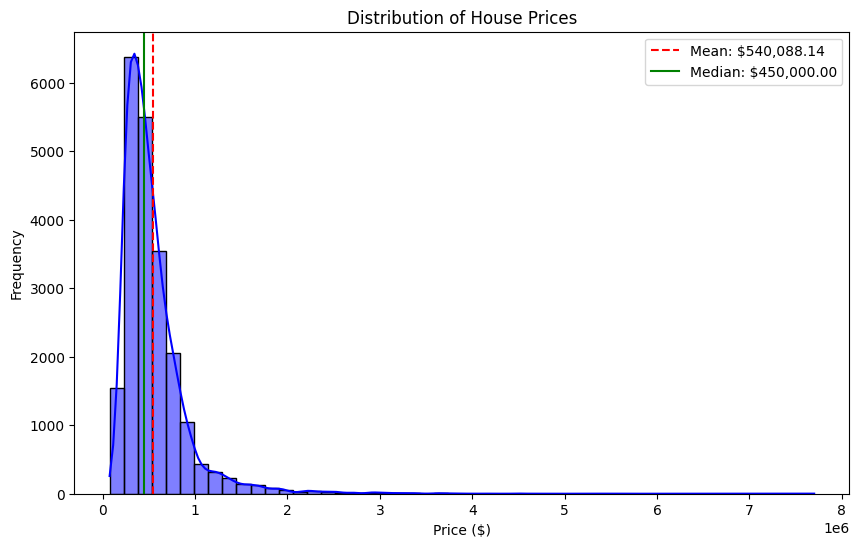

In [ ]:
# 1. Histogram of the target variable (Price)
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], bins=50, kde=True, color='blue')
plt.title('Distribution of House Prices')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')
plt.axvline(df['price'].mean(), color='red', linestyle='--', label=f"Mean: ${df['price'].mean():,.2f}")
plt.axvline(df['price'].median(), color='green', linestyle='-', label=f"Median: ${df['price'].median():,.2f}")
plt.legend()
plt.show()

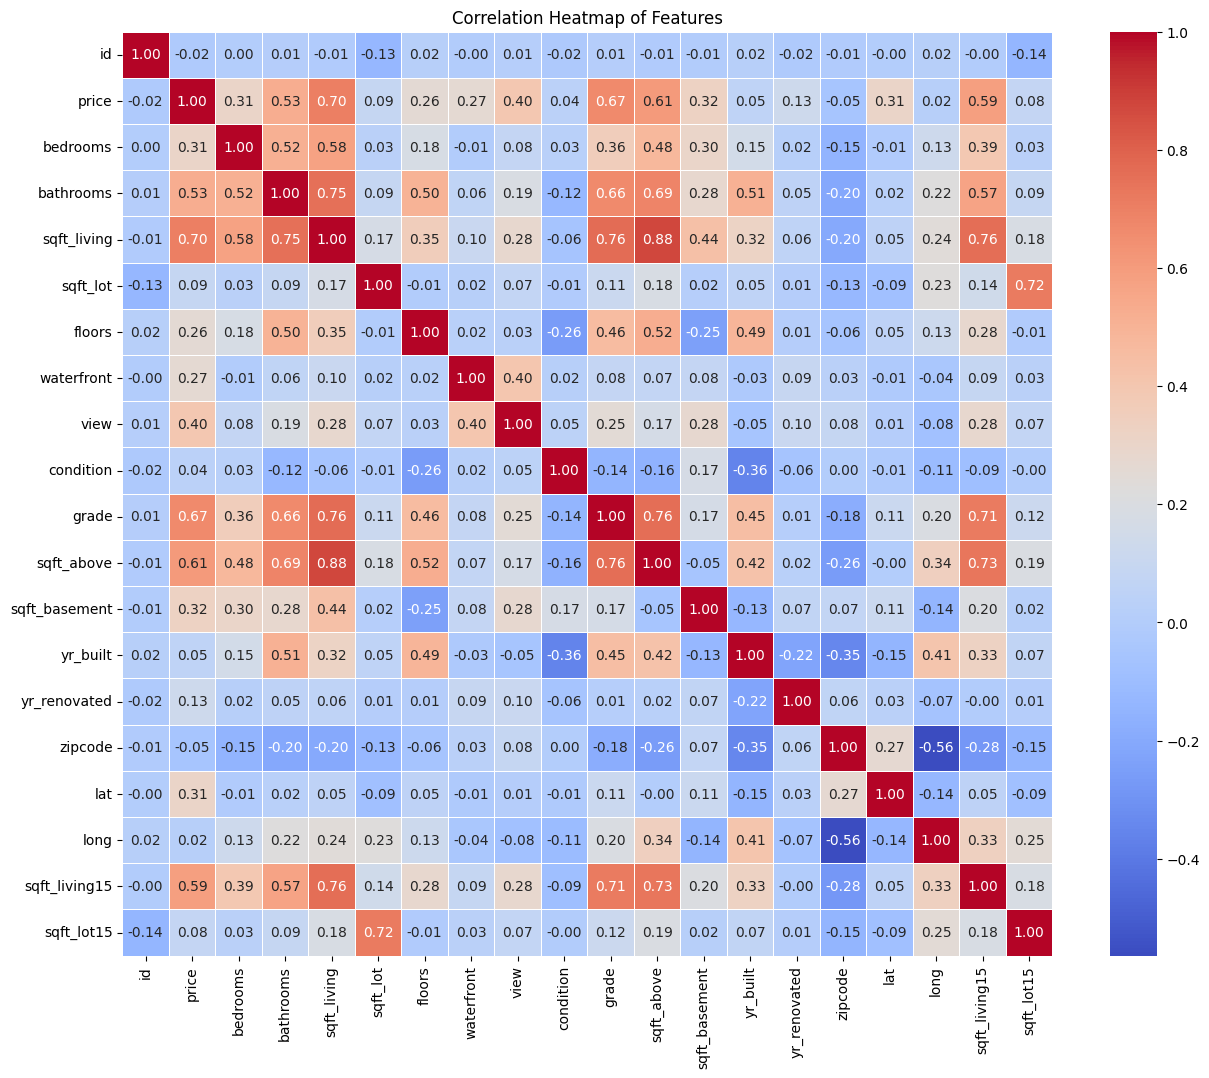

In [ ]:
# 2. Correlation heatmap
# We exclude non-numeric columns like 'date' for the correlation
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(15, 12))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.show()

According to the correlation heatmap, the target variable `price` is most strongly correlated with `sqft_living` (living area, correlation of ~0.70) and `grade` (construction quality, correlation of ~0.67). We will plot the relationship between `price` and `sqft_living`.

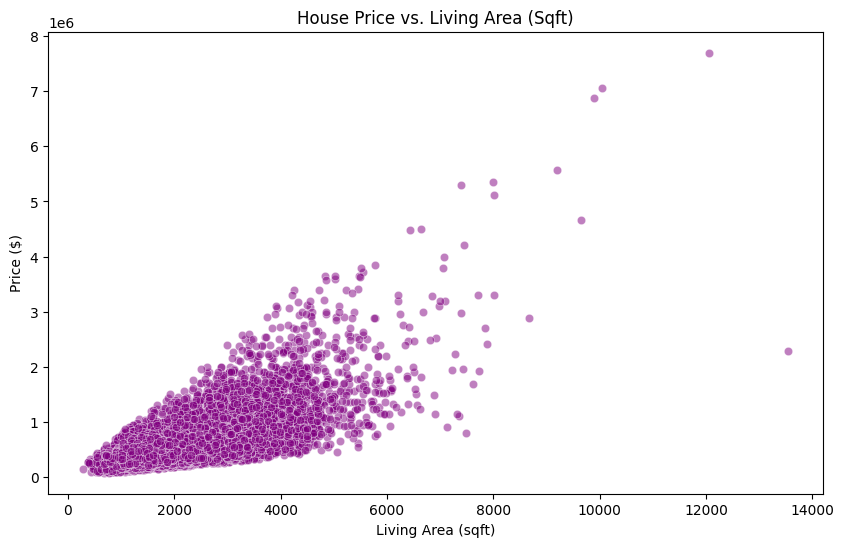

In [ ]:
# 3. Scatter plot of the top 2 correlated features (Price vs Sqft_living)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='sqft_living', y='price', data=df, alpha=0.5, color='purple')
plt.title('House Price vs. Living Area (Sqft)')
plt.xlabel('Living Area (sqft)')
plt.ylabel('Price ($)')
plt.show()